<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/D4.%20Signal%20and%20Uncertainty%20Checks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D4 Signal and Uncertainty Checks

**Diagnostic.** Reads Daily Prices and writes five reports; no other file is changed. Only holding months 2015-01 to 2019-12 are used, so the test period (2020-01 to 2026-09) stays untouched.

The replication shows that a pooled ridge model removes the overtrading of Per-ETF PTO. This notebook asks what is left in those pooled forecasts, through two checks:

| Check | Question |
|---|---|
| 1. Signal | Does pooled PTO beat 1/N or minimum variance at some trust level τ? |
| 2. Uncertainty | Do the bootstrap standard errors of the forecasts differ across ETFs, and do larger ones go with larger misses once volatility is accounted for? |

Both checks run with the paper's 9+3 window (9 months to fit, 3 to validate) and with a 60-month window.

**Criteria, fixed before the run.** Given in sections 4 and 5. ETF_A with the 9+3 window decides; ETF_B and the 60-month window are reported alongside.

**Input:** Daily Prices (`data/processed`). The monthly table, daily table, training windows and covariances are rebuilt in memory, because the saved windows and covariances cover only the test period.

**Outputs:**

| File | Folder | Contents |
|---|---|---|
| D4 Signal Check Results.csv | reports | Return, volatility, Sharpe ratio, drawdown and turnover of every run |
| D4 Signal Check Summary.csv | reports | Best PTO run against the better reference, with the reality-check p-value |
| D4 Bootstrap Errors.parquet | processed | Forecast, bootstrap standard error, volatility and realized return of every ETF and month |
| D4 Uncertainty Check Summary.csv | reports | Spread of the standard errors and their rank correlation with forecast misses |
| D4 Verdicts.csv | reports | Both checks against their criteria |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: 2ff5cb3, Replication Run (2026-10-30 16:36)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src import backtest, cleaning, config, covariance, features, forecast, windows

# Reload after a fresh clone
for module in (config, cleaning, features, windows, covariance, backtest, forecast):
    importlib.reload(module)

# Data folder paths and the selection period
DIRS = config.data_dirs()
pd.set_option("display.width", 170)
UNIVERSES = {"ETF_A": config.ETF_A, "ETF_B": config.ETF_B}
FIRST, LAST = config.SELECTION_PERIOD
verdicts = []

## 2. Data and decision calendar

Decision dates are those whose holding month falls in the selection period.

In [3]:
clean = cleaning.load_clean(DIRS["processed"])
panel = features.build_panel(clean)
table = features.build_daily_table(clean)


def calendar_for(name, first=FIRST, last=LAST):
    """Window calendar and its checks for holding months first to last.

    `windows.daily_windows` reads the test period from config, so the period is
    set for the duration of the call and restored afterwards.
    """
    saved = config.TEST_FIRST_MONTH, config.TEST_LAST_MONTH
    config.TEST_FIRST_MONTH, config.TEST_LAST_MONTH = first, last
    try:
        cal = windows.daily_windows(table, name)
        report = windows.check_daily_windows(cal, table)
    finally:
        config.TEST_FIRST_MONTH, config.TEST_LAST_MONTH = saved
    return cal, report


# Calendars for both windows, on the same decision dates
WINDOWS = ("9+3", "60")
calendars = {}
for name in WINDOWS:
    calendars[name], report = calendar_for(name)
    assert (report["status"] == "PASS").all(), report
dates = pd.DatetimeIndex(calendars["9+3"]["decision_date"])
assert (dates == pd.DatetimeIndex(calendars["60"]["decision_date"])).all()

# Holding-month returns and sample covariances at each decision date
returns = {u: panel[panel["universe"] == u].pivot(index="date", columns="ticker", values="next_return")
              .loc[dates, tickers] for u, tickers in UNIVERSES.items()}
cov_table = covariance.build_covariances(clean, dates)
cov = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in UNIVERSES}
assert all(returns[u].notna().all().all() for u in UNIVERSES)
print(f"{len(dates)} decision dates, {calendars['9+3']['month'].iloc[0]} to {calendars['9+3']['month'].iloc[-1]}")

60 decision dates, 2015-01 to 2019-12


## 3. Forecasts

One pooled ridge regression per universe on the daily rows of the training window, with the smallest penalty of the replication grid (0.1). The penalty is held fixed because the trust level τ does the shrinking.

In [4]:
# Forecasts for both windows and their quality
forecasts = {}
for name, cal in calendars.items():
    for u, tickers in UNIVERSES.items():
        forecasts[name, u] = forecast.build_forecasts(table, cal, u, tickers, alphas=[0.1])
        report = forecast.check_forecasts(forecasts[name, u], table, cal, u, tickers)
        assert (report["status"] == "PASS").all(), report

quality = pd.concat({name: forecast.forecast_quality(
    pd.concat([forecasts[name, u] for u in UNIVERSES]), panel) for name in WINDOWS},
    names=["window"])
quality.round(3)

oos_r2  mean_ic  ic_t_stat  top_pick_beats_average  spread_ratio
window universe                                                                  
9+3    ETF_A     -0.265    0.067      1.167                    0.55         0.561
       ETF_B     -0.310    0.003      0.051                    0.50         0.541
60     ETF_A     -0.010    0.169      2.619                    0.65         0.330
       ETF_B      0.017    0.144      2.618                    0.55         0.253

## 4. Check 1: signal

**Trust level.** The expected returns given to the optimizer blend the forecast f with a neutral prior π:

$$\mu_\tau = \tau \, f + (1 - \tau)\, \pi$$

- **Zero prior**, π = 0: at τ = 0 the optimizer only reduces risk, so the portfolio moves toward minimum variance.
- **Equal-weight prior**, π = 2λΣw₁/N: the expected returns under which 1/N is optimal, so at τ = 0 the portfolio stays at 1/N.

τ runs over 0 and 0.01 to 1, and λ over the paper's grid. Every run uses the replication's optimizer, sample covariance, κ = 0.005, 0.5% fee and a start from equal weights. 1/N, minimum variance and classic Markowitz run on the same months.

**Criterion.** Let S* be the Sharpe ratio of the better of 1/N and minimum variance.

- **PASS:** some PTO run with τ > 0 has a Sharpe ratio above S*, and the reality check (White, 2000) over all τ > 0 runs gives p < 0.10.
- **INCONCLUSIVE:** some run is above S*, but p ≥ 0.10.
- **FAIL:** no run is above S*.

The reality check compares the best excess Sharpe ratio across all τ > 0 runs with its distribution under 2,000 resamples of months in blocks of 3, which accounts for picking the best run after the fact.

In [5]:
TAUS = (0.0,) + tuple(config.TAU_GRID)
run_rows, nets = [], {}


def reference_key(universe, strategy):
    """Key of a reference run, which has no window, prior, λ or τ."""
    return ("-", universe, strategy, "-", None, None)


def record(key, months):
    """Store a run's metrics and monthly net returns under `key`."""
    nets[key] = months["net"].to_numpy()
    run_rows.append({**dict(zip(["window", "universe", "strategy", "prior", "lam", "tau"], key)),
                     **backtest.metrics(months)})


# References, then PTO for every window, prior, λ and τ
for u, tickers in UNIVERSES.items():
    R, n = returns[u], len(tickers)
    w_eq = np.full(n, 1 / n)
    record(reference_key(u, "1/N"), backtest.run(backtest.equal_weight(n), R)[0])
    record(reference_key(u, "Minimum variance"), backtest.run(backtest.minimum_variance(cov[u]), R)[0])
    hist = backtest.historical_means(clean, dates, u)
    for lam in config.LAMBDA_GRID:
        record(("-", u, "Classic Markowitz", "-", lam, None),
               backtest.run(backtest.mean_variance(hist, cov[u], lam), R)[0])
        priors = {"zero": pd.DataFrame(0.0, index=dates, columns=tickers),
                  "equal weight": pd.DataFrame([2 * lam * cov[u][d] @ w_eq for d in dates],
                                               index=dates, columns=tickers)}
        for name in WINDOWS:
            f = forecasts[name, u].pivot(index="date", columns="ticker", values="forecast").loc[dates, tickers]
            for prior, pi in priors.items():
                for tau in TAUS:
                    mu = tau * f + (1 - tau) * pi
                    record((name, u, "PTO", prior, lam, tau),
                           backtest.run(backtest.mean_variance(mu, cov[u], lam), R)[0])

results = pd.DataFrame(run_rows)
(results[results["strategy"] != "PTO"]
 .set_index(["universe", "strategy", "lam"])[["ann_return", "ann_vol", "sharpe", "turnover"]].round(3))

ann_return  ann_vol  sharpe  turnover
universe strategy          lam                                        
ETF_A    1/N               NaN        0.079    0.100   0.793     0.008
         Minimum variance  NaN        0.033    0.029   1.156     0.037
         Classic Markowitz 0.1        0.051    0.140   0.365     0.142
                           1.0        0.071    0.126   0.564     0.150
                           10.0       0.066    0.063   1.045     0.093
                           20.0       0.047    0.044   1.062     0.069
                           50.0       0.038    0.032   1.176     0.040
ETF_B    1/N               NaN        0.110    0.127   0.871     0.009
         Minimum variance  NaN        0.076    0.106   0.717     0.084
         Classic Markowitz 0.1        0.079    0.143   0.553     0.180
                           1.0        0.078    0.137   0.572     0.177
                           10.0       0.083    0.117   0.706     0.121
                           20.0       0.076    0.111   0.682     0.105
                           50.0       0.076    0.105   0.726     0.073

### Sharpe ratio by trust level

9+3 window. Each line is one λ; the dashed and dotted lines are 1/N and minimum variance.

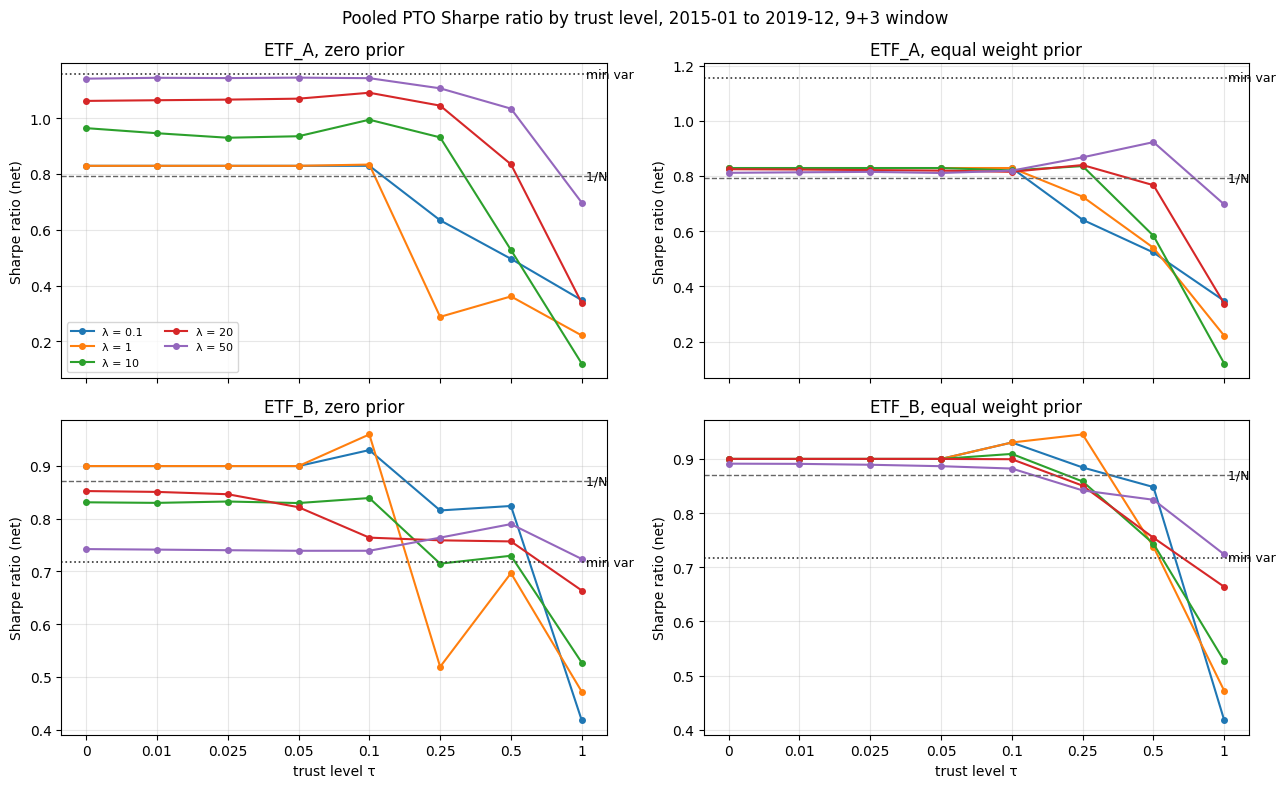

In [6]:
# One panel per universe and prior
pto = results[results["strategy"] == "PTO"]
ref = results[results["strategy"].isin(["1/N", "Minimum variance"])].set_index(["universe", "strategy"])["sharpe"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
x = np.arange(len(TAUS))
for row, u in enumerate(UNIVERSES):
    for col, prior in enumerate(["zero", "equal weight"]):
        ax = axes[row, col]
        for lam in config.LAMBDA_GRID:
            s = pto[(pto["window"] == "9+3") & (pto["universe"] == u) & (pto["prior"] == prior)
                    & (pto["lam"] == lam)].set_index("tau")["sharpe"].reindex(TAUS)
            ax.plot(x, s.to_numpy(), marker="o", ms=4, lw=1.5, label=f"λ = {lam:g}")
        ax.axhline(ref[u, "1/N"], color="0.4", ls="--", lw=1)
        ax.axhline(ref[u, "Minimum variance"], color="0.2", ls=":", lw=1.2)
        ax.text(len(TAUS) - 1, ref[u, "1/N"], " 1/N", va="center", fontsize=9)
        ax.text(len(TAUS) - 1, ref[u, "Minimum variance"], " min var", va="center", fontsize=9)
        ax.set_title(f"{u}, {prior} prior")
        ax.set_xticks(x, [f"{t:g}" for t in TAUS])
        ax.set_ylabel("Sharpe ratio (net)")
        ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("trust level τ")
axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle("Pooled PTO Sharpe ratio by trust level, 2015-01 to 2019-12, 9+3 window")
fig.tight_layout()
plt.show()

In [7]:
# Sharpe ratio by trust level, 9+3 window
pto[pto["window"] == "9+3"].pivot_table(index=["universe", "prior", "lam"], columns="tau", values="sharpe").round(2)

tau                         0.000  0.010  0.025  0.050  0.100  0.250  0.500  1.000
universe prior        lam                                                         
ETF_A    equal weight 0.1    0.83   0.83   0.83   0.83   0.83   0.64   0.52   0.35
                      1.0    0.83   0.83   0.83   0.83   0.83   0.72   0.54   0.22
                      10.0   0.83   0.83   0.83   0.83   0.82   0.84   0.58   0.12
                      20.0   0.82   0.82   0.82   0.82   0.82   0.84   0.77   0.34
                      50.0   0.81   0.81   0.81   0.81   0.82   0.87   0.92   0.70
         zero         0.1    0.83   0.83   0.83   0.83   0.83   0.63   0.50   0.35
                      1.0    0.83   0.83   0.83   0.83   0.83   0.29   0.36   0.22
                      10.0   0.96   0.95   0.93   0.93   0.99   0.93   0.53   0.12
                      20.0   1.06   1.06   1.07   1.07   1.09   1.04   0.83   0.34
                      50.0   1.14   1.14   1.14   1.14   1.14   1.11   1.03   0.70
ETF_B    equal weight 0.1    0.90   0.90   0.90   0.90   0.93   0.88   0.85   0.42
                      1.0    0.90   0.90   0.90   0.90   0.93   0.94   0.74   0.47
                      10.0   0.90   0.90   0.90   0.90   0.91   0.86   0.74   0.53
                      20.0   0.90   0.90   0.90   0.90   0.90   0.85   0.75   0.66
                      50.0   0.89   0.89   0.89   0.89   0.88   0.84   0.82   0.72
         zero         0.1    0.90   0.90   0.90   0.90   0.93   0.82   0.82   0.42
                      1.0    0.90   0.90   0.90   0.90   0.96   0.52   0.70   0.47
                      10.0   0.83   0.83   0.83   0.83   0.84   0.71   0.73   0.53
                      20.0   0.85   0.85   0.85   0.82   0.76   0.76   0.76   0.66
                      50.0   0.74   0.74   0.74   0.74   0.74   0.76   0.79   0.72

### Reality check and verdict

In [8]:
def block_index(n, block, rng):
    """Indices of a circular block resample of n periods."""
    starts = rng.integers(0, n, int(np.ceil(n / block)))
    return (np.concatenate([np.arange(s, s + block) for s in starts]) % n)[:n]


def annual_sharpe(x):
    """Annualized Sharpe ratio of monthly returns, column by column."""
    return x.mean(axis=0) / x.std(axis=0, ddof=1) * np.sqrt(12)


def reality_check(candidates, benchmark, resamples=2000, block=3, seed=0):
    """Best excess Sharpe ratio over the benchmark and its White (2000) p-value."""
    rng = np.random.default_rng(seed)
    X, b = np.column_stack(candidates), np.asarray(benchmark)
    excess = annual_sharpe(X) - annual_sharpe(b[:, None])
    best = excess.max()
    hits = 0
    for _ in range(resamples):
        i = block_index(len(b), block, rng)
        hits += (annual_sharpe(X[i]) - annual_sharpe(b[i][:, None]) - excess).max() >= best
    return best, hits / resamples


# Best τ > 0 run against the better reference, per window and universe
check1 = []
for name in WINDOWS:
    for u in UNIVERSES:
        refs = {s: nets[reference_key(u, s)] for s in ("1/N", "Minimum variance")}
        bench_name = max(refs, key=lambda s: annual_sharpe(refs[s]))
        keys = [k for k in nets if k[0] == name and k[1] == u and k[2] == "PTO" and k[5] > 0]
        excess, p = reality_check([nets[k] for k in keys], refs[bench_name])
        best_key = max(keys, key=lambda k: annual_sharpe(nets[k]))
        status = "FAIL" if excess <= 0 else ("PASS" if p < 0.10 else "INCONCLUSIVE")
        check1.append({"window": name, "universe": u, "benchmark": bench_name,
                       "benchmark_sharpe": annual_sharpe(refs[bench_name]),
                       "best_pto_sharpe": annual_sharpe(nets[best_key]),
                       "best_run": f"{best_key[3]} prior, λ = {best_key[4]:g}, τ = {best_key[5]:g}",
                       "excess": excess, "p_value": p, "status": status})
check1 = pd.DataFrame(check1)

d = check1[(check1["window"] == "9+3") & (check1["universe"] == "ETF_A")].iloc[0]
verdicts.append({"check": "1", "question": "PTO beats 1/N or minimum variance at some τ > 0 (ETF_A, 9+3)",
                 "status": d["status"],
                 "detail": f"best PTO Sharpe {d['best_pto_sharpe']:.2f} ({d['best_run']}) "
                           f"vs {d['benchmark']} {d['benchmark_sharpe']:.2f}; reality-check p = {d['p_value']:.2f}"})
check1.round(3)

,window,universe,benchmark,benchmark_sharpe,best_pto_sharpe,best_run,excess,p_value,status
0,9+3,ETF_A,Minimum variance,1.156,1.145,"zero prior, λ = 50, τ = 0.05",-0.012,0.866,FAIL
1,9+3,ETF_B,1/N,0.871,0.960,"zero prior, λ = 1, τ = 0.1",0.089,0.806,INCONCLUSIVE
2,60,ETF_A,Minimum variance,1.156,1.288,"zero prior, λ = 50, τ = 1",0.132,0.566,INCONCLUSIVE
3,60,ETF_B,1/N,0.871,1.105,"zero prior, λ = 0.1, τ = 1",0.235,0.420,INCONCLUSIVE


### Gain over τ = 0

For each prior and λ, the change in Sharpe ratio between τ = 0 (no forecast) and the best τ > 0.

In [9]:
# Sharpe ratio at τ = 0, best τ > 0 and the difference
group = ["window", "universe", "prior", "lam"]
base = pto[pto["tau"] == 0].set_index(group)["sharpe"]
best = pto[pto["tau"] > 0].groupby(group)["sharpe"].max()
best_tau = pto[pto["tau"] > 0].sort_values("sharpe").groupby(group)["tau"].last()
pd.DataFrame({"sharpe_tau_0": base, "best_sharpe": best, "best_tau": best_tau, "gain": best - base}).round(3)

sharpe_tau_0  best_sharpe  best_tau   gain
window universe prior        lam                                             
60     ETF_A    equal weight 0.1          0.829        1.192     1.000  0.363
                             1.0          0.829        1.192     1.000  0.363
                             10.0         0.829        1.107     1.000  0.278
                             20.0         0.825        1.179     1.000  0.355
                             50.0         0.811        1.288     1.000  0.477
                zero         0.1          0.829        1.192     1.000  0.363
                             1.0          0.829        1.192     1.000  0.363
                             10.0         0.964        1.141     0.500  0.177
                             20.0         1.061        1.187     0.500  0.126
                             50.0         1.141        1.288     1.000  0.147
       ETF_B    equal weight 0.1          0.900        1.105     1.000  0.206
                             1.0          0.900        1.063     1.000  0.163
                             10.0         0.900        0.987     1.000  0.087
                             20.0         0.900        0.926     0.250  0.026
                             50.0         0.891        0.893     0.100  0.002
                zero         0.1          0.900        1.105     1.000  0.206
                             1.0          0.900        1.063     1.000  0.163
                             10.0         0.831        0.987     1.000  0.156
                             20.0         0.852        0.888     1.000  0.036
                             50.0         0.742        0.837     1.000  0.095
9+3    ETF_A    equal weight 0.1          0.829        0.829     0.100  0.000
                             1.0          0.829        0.829     0.025  0.000
                             10.0         0.829        0.836     0.250  0.007
                             20.0         0.825        0.840     0.250  0.015
                             50.0         0.811        0.923     0.500  0.111
                zero         0.1          0.829        0.829     0.025  0.000
                             1.0          0.829        0.833     0.100  0.005
                             10.0         0.964        0.994     0.100  0.030
                             20.0         1.061        1.091     0.100  0.029
                             50.0         1.141        1.145     0.050  0.004
       ETF_B    equal weight 0.1          0.900        0.930     0.100  0.030
                             1.0          0.900        0.945     0.250  0.045
                             10.0         0.900        0.909     0.100  0.009
                             20.0         0.900        0.900     0.050  0.000
                             50.0         0.891        0.891     0.010 -0.000
                zero         0.1          0.900        0.930     0.100  0.030
                             1.0          0.900        0.960     0.100  0.060
                             10.0         0.831        0.839     0.100  0.008
                             20.0         0.852        0.851     0.010 -0.002
                             50.0         0.742        0.790     0.500  0.047

## 5. Check 2: uncertainty

**Bootstrap.** At each decision date, the pooled ridge model is refit 100 times on resampled training data and predicts the coming month each time. Months of the training window are resampled in blocks of 3, so the overlap between neighbouring daily rows stays intact. The standard deviation of an ETF's 100 predictions is its bootstrap standard error (SE).

**Volatility adjustment.** Volatile ETFs have larger SEs and larger misses because their returns move more, and the optimizer already accounts for that through the covariance. The SE adds information only if SE / σ, the SE in units of the ETF's monthly volatility, predicts |miss| / σ. Raw and adjusted versions are both reported.

**Criterion.** Check 2 passes when both parts pass.

- **2a, SEs differ:** the median over months of max SE / min SE across ETFs is at least 1.5.
- **2b, SEs predict misses beyond volatility:** the mean monthly rank correlation between SE / σ and |forecast − realized| / σ is positive with a t-statistic of at least 2.

In [10]:
def bootstrap_month(step, universe, tickers, rng, alpha=0.1,
                    refits=config.BOOTSTRAP_REFITS, block=config.BOOTSTRAP_BLOCK_MONTHS):
    """Refits x ETFs matrix of forecasts from block-resampled training windows."""
    fit, val, test = windows.daily_rows_for(table, step, universe)
    rows = pd.concat([fit, val])
    months = rows["date"].dt.to_period("M").to_numpy()
    unique = pd.unique(months)
    members = [np.flatnonzero(months == m) for m in unique]
    out = np.empty((refits, len(tickers)))
    for b in range(refits):
        idx = np.concatenate([members[i] for i in block_index(len(unique), block, rng)])
        sample = rows.iloc[idx]
        x, center, scale = forecast._design(sample, tickers)
        b0, beta = forecast.ridge_fit(x, sample["fwd_return"].to_numpy(), [alpha])[0]
        x_test, _, _ = forecast._design(test, tickers, center, scale)
        out[b] = pd.Series(b0 + x_test @ beta, index=test["ticker"].to_numpy()).reindex(tickers)
    return out


# Bootstrap SE and volatility for every window, ETF and month
rng = np.random.default_rng(0)
boot_rows = []
for name, cal in calendars.items():
    for u, tickers in UNIVERSES.items():
        for _, step in cal.iterrows():
            draws = bootstrap_month(step, u, tickers, rng)
            d = step["decision_date"]
            sigma = np.sqrt(np.diag(cov[u][d]))
            for i, t in enumerate(tickers):
                boot_rows.append({"window": name, "universe": u, "date": d, "ticker": t,
                                  "boot_mean": draws[:, i].mean(), "se": draws[:, i].std(ddof=1),
                                  "sigma": sigma[i]})

# Forecasts, realized returns and misses
fc_all = pd.concat({name: pd.concat([forecasts[name, u] for u in UNIVERSES]) for name in WINDOWS},
                   names=["window"]).reset_index(level=0)
boot = (pd.DataFrame(boot_rows)
        .merge(fc_all[["window", "date", "universe", "ticker", "forecast"]], on=["window", "date", "universe", "ticker"])
        .merge(panel[["date", "universe", "ticker", "next_return"]], on=["date", "universe", "ticker"]))
boot["miss"] = (boot["forecast"] - boot["next_return"]).abs()
boot["se_rel"] = boot["se"] / boot["sigma"]
boot["miss_rel"] = boot["miss"] / boot["sigma"]
assert len(boot) == len(WINDOWS) * len(dates) * sum(len(t) for t in UNIVERSES.values())
assert boot[["se", "forecast", "next_return"]].notna().all().all()

### Standard errors across ETFs

In [11]:
# Average SE, volatility and SE / volatility per ETF, 9+3 window
(boot[boot["window"] == "9+3"].groupby(["universe", "ticker"])[["se", "sigma", "se_rel"]].mean()
 .sort_values(["universe", "se"]).round(4))

se   sigma  se_rel
universe ticker                        
ETF_A    AGG     0.0056  0.0099  0.5791
         SPY     0.0112  0.0379  0.2881
         VTI     0.0116  0.0381  0.2962
         EFA     0.0120  0.0403  0.2998
         JPXN    0.0128  0.0445  0.2844
         XLK     0.0137  0.0484  0.2703
         EEM     0.0178  0.0539  0.3250
         DBC     0.0189  0.0441  0.4236
ETF_B    SPY     0.0119  0.0379  0.3080
         XLP     0.0121  0.0342  0.3598
         XLK     0.0134  0.0484  0.2679
         QQQ     0.0139  0.0482  0.2828
         XLY     0.0140  0.0421  0.3343
         XLV     0.0145  0.0434  0.3364
         XLI     0.0146  0.0433  0.3298
         IWM     0.0155  0.0470  0.3202
         XLF     0.0162  0.0483  0.3352
         XLE     0.0235  0.0611  0.3906

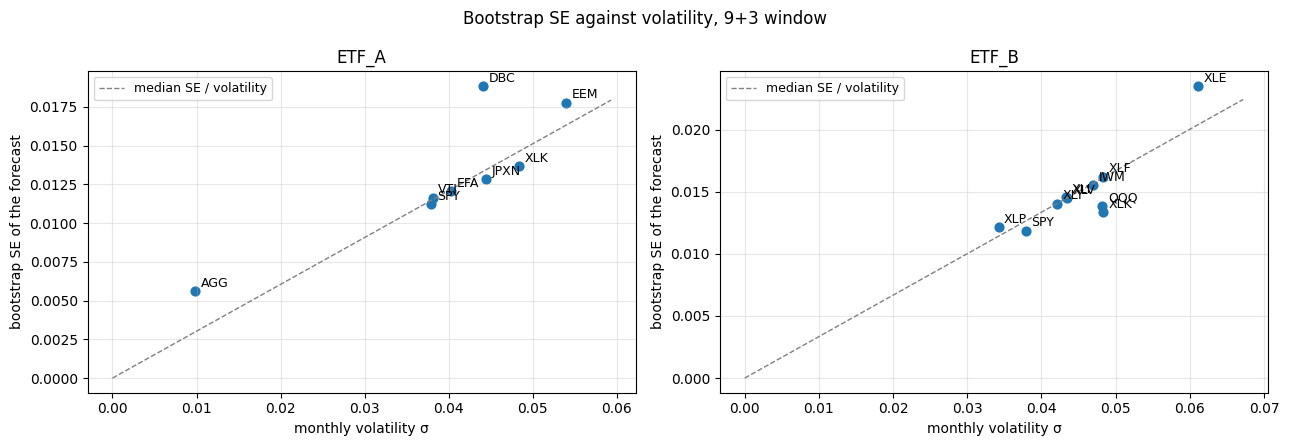

In [12]:
# SE against volatility, average per ETF
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, u in zip(axes, UNIVERSES):
    b = boot[(boot["window"] == "9+3") & (boot["universe"] == u)].groupby("ticker")[["se", "sigma"]].mean()
    ax.scatter(b["sigma"], b["se"], s=40)
    for t, r in b.iterrows():
        ax.annotate(t, (r["sigma"], r["se"]), xytext=(4, 3), textcoords="offset points", fontsize=9)
    lim = np.array([0, b["sigma"].max() * 1.1])
    ax.plot(lim, lim * (b["se"] / b["sigma"]).median(), color="0.5", ls="--", lw=1,
            label="median SE / volatility")
    ax.set_xlabel("monthly volatility σ")
    ax.set_ylabel("bootstrap SE of the forecast")
    ax.set_title(u)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
fig.suptitle("Bootstrap SE against volatility, 9+3 window")
fig.tight_layout()
plt.show()

### Standard errors and misses

Each month, the rank correlation across ETFs between the SE and the absolute forecast error, raw and volatility-adjusted. The last column is the share of forecasts more than two SEs from the universe average.

In [13]:
def monthly_rank_corr(df, a, b):
    """Rank correlation between columns a and b across ETFs, one value per month."""
    return df.groupby("date").apply(lambda g: spearmanr(g[a], g[b])[0])


# Spread of the SEs and their link to misses, per window and universe
check2 = []
for (name, u), b in boot.groupby(["window", "universe"], sort=False):
    ratio = b.groupby("date")["se"].agg(lambda s: s.max() / s.min())
    raw = monthly_rank_corr(b, "se", "miss")
    adj = monthly_rank_corr(b, "se_rel", "miss_rel")
    distance = (b["forecast"] - b.groupby("date")["forecast"].transform("mean")).abs()
    check2.append({"window": name, "universe": u,
                   "median_max_min_se": ratio.median(),
                   "corr_se_sigma": spearmanr(b["se"], b["sigma"])[0],
                   "raw_corr": raw.mean(), "raw_t": raw.mean() / raw.std() * np.sqrt(len(raw)),
                   "adj_corr": adj.mean(), "adj_t": adj.mean() / adj.std() * np.sqrt(len(adj)),
                   "share_beyond_2_se": (distance > 2 * b["se"]).mean()})
check2 = pd.DataFrame(check2)
check2.round(3)

/tmp/ipykernel_805/719101096.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("date").apply(lambda g: spearmanr(g[a], g[b])[0])
/tmp/ipykernel_805/719101096.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("date").apply(lambda g: spearmanr(g[a], g[b])[0])
/tmp/ipykernel_805/719101096.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. 

,window,universe,median_max_min_se,corr_se_sigma,raw_corr,raw_t,adj_corr,adj_t,share_beyond_2_se
0,9+3,ETF_A,4.315,0.722,0.337,7.552,0.093,1.588,0.123
1,9+3,ETF_B,3.029,0.603,0.173,3.812,0.075,1.585,0.065
2,60,ETF_A,4.024,0.642,0.380,8.851,-0.054,-0.969,0.117
3,60,ETF_B,2.326,0.488,0.219,4.782,0.077,1.531,0.032


/tmp/ipykernel_805/719101096.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("date").apply(lambda g: spearmanr(g[a], g[b])[0])
/tmp/ipykernel_805/719101096.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("date").apply(lambda g: spearmanr(g[a], g[b])[0])
/tmp/ipykernel_805/719101096.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. 

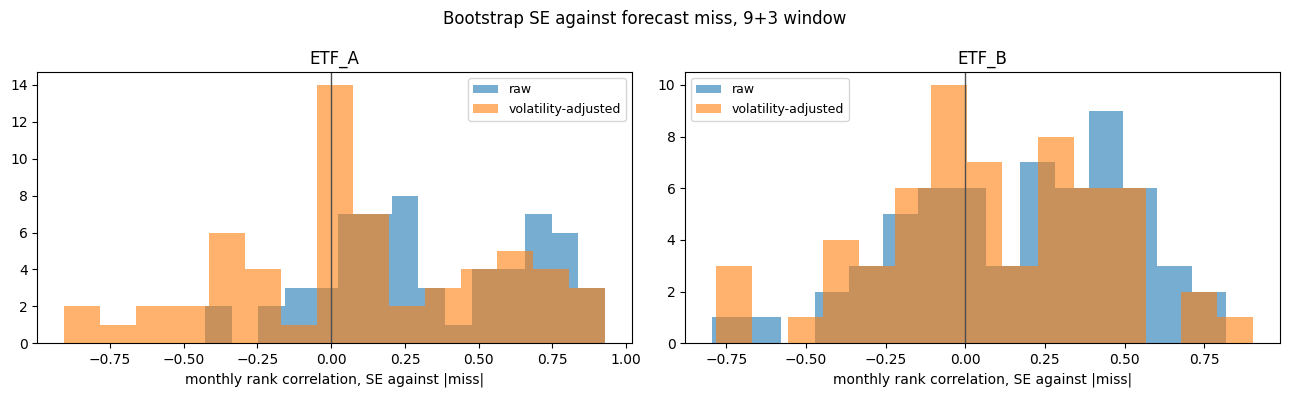

In [14]:
# Monthly rank correlations, raw and volatility-adjusted
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, u in zip(axes, UNIVERSES):
    b = boot[(boot["window"] == "9+3") & (boot["universe"] == u)]
    ax.hist(monthly_rank_corr(b, "se", "miss"), bins=15, alpha=0.6, label="raw")
    ax.hist(monthly_rank_corr(b, "se_rel", "miss_rel"), bins=15, alpha=0.6, label="volatility-adjusted")
    ax.axvline(0, color="0.3", lw=1)
    ax.set_title(u)
    ax.set_xlabel("monthly rank correlation, SE against |miss|")
    ax.legend(fontsize=9)
fig.suptitle("Bootstrap SE against forecast miss, 9+3 window")
fig.tight_layout()
plt.show()

In [15]:
# Verdicts for 2a, 2b and check 2
d = check2[(check2["window"] == "9+3") & (check2["universe"] == "ETF_A")].iloc[0]
a_ok = d["median_max_min_se"] >= 1.5
b_ok = d["adj_corr"] > 0 and d["adj_t"] >= 2
verdicts += [
    {"check": "2a", "question": "SEs differ across ETFs (ETF_A, 9+3)", "status": "PASS" if a_ok else "FAIL",
     "detail": f"median max/min SE {d['median_max_min_se']:.2f}; rank correlation with volatility "
               f"{d['corr_se_sigma']:.2f}"},
    {"check": "2b", "question": "SE / σ predicts |miss| / σ (ETF_A, 9+3)", "status": "PASS" if b_ok else "FAIL",
     "detail": f"mean rank correlation {d['adj_corr']:.3f}, t = {d['adj_t']:.2f} "
               f"(raw {d['raw_corr']:.3f}, t = {d['raw_t']:.2f})"},
    {"check": "2", "question": "Check 2 overall", "status": "PASS" if a_ok and b_ok else "FAIL",
     "detail": "both 2a and 2b must pass"},
]
verdicts = pd.DataFrame(verdicts)
verdicts

,check,question,status,detail
0,1,PTO beats 1/N or minimum variance at some τ > ...,FAIL,"best PTO Sharpe 1.14 (zero prior, λ = 50, τ = ..."
1,2a,"SEs differ across ETFs (ETF_A, 9+3)",PASS,median max/min SE 4.31; rank correlation with ...
2,2b,"SE / σ predicts |miss| / σ (ETF_A, 9+3)",FAIL,"mean rank correlation 0.093, t = 1.59 (raw 0.3..."
3,2,Check 2 overall,FAIL,both 2a and 2b must pass


## 6. Save

In [16]:
results.to_csv(DIRS["reports"] / "D4 Signal Check Results.csv", index=False)
check1.to_csv(DIRS["reports"] / "D4 Signal Check Summary.csv", index=False)
boot.to_parquet(DIRS["processed"] / "D4 Bootstrap Errors.parquet", index=False)
check2.to_csv(DIRS["reports"] / "D4 Uncertainty Check Summary.csv", index=False)
verdicts.to_csv(DIRS["reports"] / "D4 Verdicts.csv", index=False)